# การวิเคราะห์และจำแนกประเภทศิลปกรรมวัดพระธาตุลำปางหลวงแบบ Zero-shot ด้วยแบบจำลอง CLIP

สมุดบันทึก (Notebook) เล่มนี้จัดทำขึ้นเพื่อประกอบการปรับปรุงบทความวิจัย (วารสารวิทยาศาสตร์ บูรพา) โดยระบบจะทำการสร้างตารางผลการทดลองทั้งหมด (Table 1–6) และแผนภาพ Confusion Matrix (Figure 2–5) ที่ปรากฏในเล่มรายงาน

*หมายเหตุ: สำหรับ Figure 1 ซึ่งเป็นภาพตัวอย่างศิลปกรรม จะไม่ได้สร้างจากโค้ดในเล่มนี้ การประมวลผลทั้งหมดใช้เวลาบนระบบ Google Colab (GPU Tesla T4)*

### แผนผังการเชื่อมโยงผลการทดลองในบทความกับโค้ดในแต่ละส่วน

| หัวข้อในบทความ | เซลล์ประมวลผล | ไฟล์ผลลัพธ์ที่บันทึก | รายละเอียดเพิ่มเติม |
|---|---|---|---|
| **Table 1** จำนวนภาพจำแนกตามประเภท | A1 | `table1_dataset.csv` | รายละเอียดศิลปกรรม 18 รายการย่อย อธิบายไว้ในส่วนที่ 1 |
| **Table 2** ค่าประสิทธิภาพจำแนกภาพ | A2, A3, B1 | `zero_shot_all_conditions.csv` | แสดงค่า top-1, top-3 และ macro-F1 ของทั้ง 4 Backbone |
| **Table 2 & 5** ช่วงความเชื่อมั่น 95% (CI) | B2, B5 | `bootstrap_ci.csv`<br>`prompt_language_controlled.csv` | คำนวณความคลาดเคลื่อนด้วยวิธีสุ่มซ้ำ (Bootstrap) |
| **Table 3** ค่า F1-score แยกตามประเภท | A3 | `table3_per_class_f1.csv`<br>`per_class_precision_recall_f1.csv` | รายงานผลการจำแนกรายละเอียดศิลปกรรมแต่ละกลุ่ม |
| **Figure 2–5** Confusion Matrix | A4 | `cm_<Backbone>.png` | แผนภูมิความสับสนจากการทดสอบด้วยพรอมป์ต์ทั่วไป |
| **Table 4** ผลของการเพิ่มบริบทในพรอมป์ต์ | A3, B3 | `zero_shot_all_conditions.csv`<br>`mcnemar.csv` | เปรียบเทียบพรอมป์ต์ทั่วไป กับพรอมป์ต์แบบเฉพาะเจาะจง (McNemar) |
| **Table 5** อิทธิพลของภาษาในพรอมป์ต์ | B5 | `prompt_language_controlled.csv`<br>`mcnemar_language_controlled.csv` | ทดสอบเปรียบเทียบระหว่าง EN-4, EN-2, TH-mixed และ TH-full |
| **Table 6** การเปรียบเทียบ Zero-shot กับ Linear Probe | B4 | `fewshot_same_test_set.csv`<br>`fewshot_mcnemar_per_seed.csv` | ประเมินผลบนชุดข้อมูลทดสอบเดียวกันเพื่อความเที่ยงตรง |
| **พรอมป์ต์ที่ใช้งานจริง** | B6 | `all_prompts.csv` | บันทึกข้อความสั่งการ (Prompts) ทั้งหมดที่ใช้ในการวิจัย |
| **ระบบตรวจความถูกต้องของข้อมูล** | A6, B7 | (พิมพ์ผลการตรวจสอบบนจอภาพ) | ตรวจสอบความถูกต้องเปรียบเทียบกับตัวเลขในบทความจริง |

*หมายเหตุ: เซลล์ประมวลผล A5 เป็นการจำแนกแบบ Linear Probe ตามกระบวนการทำงานแบบเดิม (โปรโตคอลก่อนปรับแก้) ซึ่งไม่ได้นำไปรายงานผลในตัวบทความหลัก ทางคณะผู้วิจัยคงค่าส่วนนี้ไว้เพื่อใช้เป็นข้อมูลอ้างอิงภายในเท่านั้น*

---

### ความสอดคล้องระหว่างสมการในบทความวิจัยกับชุดคำสั่งในโปรแกรม

การคำนวณและประมวลผลในโค้ดนี้ถูกออกแบบให้ตรงกับระเบียบวิธีวิจัย (Methodology) ข้อ 3 และข้อ 7 ดังนี้

* **การแปลงรูปภาพเป็นเวกเตอร์คุณลักษณะ (Feature Extraction)** ตามสมการ (1):
  $$v = f_I(x)/\lVert f_I(x)\rVert_2$$
  สอดคล้องกับฟังก์ชัน `encode_images()`
* **การสร้างชุดคำอธิบายประเภทศิลปกรรม** (นิยามชุดพรอมป์ต์ $\mathcal{T}_k=\{t_m(d_j)\}$):
  สอดคล้องกับฟังก์ชัน `build_prompt_set()`
* **การคำนวณตัวแทนของประเภทศิลปกรรม (Class Prototypes)** ตามสมการ (2):
  $$u_k=\mathrm{norm}\big(\frac{1}{\lvert\mathcal{T}_k\rvert}\sum_{p\in\mathcal{T}_k} f_T(p)/\lVert f_T(p)\rVert_2\big)$$
  สอดคล้องกับฟังก์ชัน `class_prototypes()`
* **การทำนายและจัดหมวดหมู่ภาพศิลปกรรม** ตามสมการ (3):
  $$\hat y=\arg\max_k\, s\cdot(v^\top u_k)$$
  สอดคล้องกับฟังก์ชัน `zero_shot_scores()` และ `predict()`
* **การประเมินประสิทธิภาพการวัดผลแยกตามประเภทศิลปกรรม (Per-class Metrics)**:
  * ค่าความแม่นยำ (Precision) ตามสมการ (4): $P_k = TP_k/(TP_k+FP_k)$
  * ค่าความระลึก (Recall) ตามสมการ (5): $R_k = TP_k/(TP_k+FN_k)$
  * ค่าคะแนนเอฟวัน (F1-Score) ตามสมการ (6): $F1_k = 2P_kR_k/(P_k+R_k)$
  * ค่าเฉลี่ยคะแนนเอฟวันรวม (macro-F1): $\frac{1}{K}\sum_{k=1}^{K}F1_k$
  ทั้งหมดคำนวณผ่านฟังก์ชัน `per_class_metrics()` และมีการสอบทานความถูกต้องกับคลังเครื่องมือมาตรฐาน `scikit-learn` เพื่อความแม่นยำสูงสุด

### กระบวนการทางสถิติและวิธีการทดสอบเปรียบเทียบ
1. **ช่วงความเชื่อมั่น 95% (95% Confidence Interval):** ใช้วิธี Percentile Bootstrap สุ่มกลุ่มตัวอย่างซ้ำแบบใส่คืนจำนวน 10,000 รอบ โดยใช้ชุดดัชนีภาพเดียวกัน (Paired Index) ในการประเมินผลทุกรูปแบบเพื่อป้องกันความคลาดเคลื่อน
2. **การทดสอบความแตกต่างอย่างมีนัยสำคัญ:** ใช้สถิติ McNemar Exact Test ในการเปรียบเทียบประสิทธิภาพการประเมินรายคู่บนภาพชุดเดียวกัน สำหรับชุดการทดสอบ Zero-shot จะแสดงผลลัพธ์เป็นค่า p-value แบบดิบ (`p_exact`) เพื่อใช้อ้างอิงในบทความหลัก และได้คำนวณค่า p-value แบบปรับแล้วด้วยวิธีของ Holm (`p_holm`) แยกไว้ให้เป็นข้อมูลเสริม
3. **การทดสอบการเรียนรู้จากตัวอย่างน้อย (Few-shot Comparison):** ในขั้นตอนเปรียบเทียบระหว่าง Zero-shot และ Linear Probe (ในเซลล์ B4) ระบบจะใช้วิธีหาค่ามัธยฐาน (Median) ของค่า p-value ดิบจากการสุ่มทดลอง 5 รอบ และปรับค่าทางสถิติด้วยวิธีของ Holm ครอบคลุมค่า k ทั้ง 4 ช่วง (k = 1, 2, 4, 8) เพื่อควบคุม family-wise error

## ส่วนที่ 0: การเตรียมความพร้อมระบบและการเชื่อมโยงข้อมูล

In [23]:
# 0.1 ติดตั้งไลบรารี
!pip -q install open_clip_torch==3.3.0   # เวอร์ชันเดียวกับที่รายงานในบทความ (Methodology ข้อ 6)

In [24]:
# 0.2 เชื่อม Google Drive และตั้งค่าโฟลเดอร์
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/xxxxxxxxxx/Images-AppLampangLuang'  # <-- แก้ให้ตรง (โฟลเดอร์ภาพ CCC_KKK_II.jpg)
OUT_DIR  = '/content/drive/MyDrive/xxxxxxxxxx/results_rev5'                 # <-- โฟลเดอร์ผลลัพธ์
FIG_DPI  = 300            # ความละเอียดรูป confusion matrix (บทความระบุ 300 dpi)
N_BOOT   = 10000          # จำนวนรอบ bootstrap
BOOT_SEED = 42
FEWSHOT_SEEDS = [0, 1, 2, 3, 4]
FEWSHOT_K = [1, 2, 4, 8]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
# 0.3 import และบันทึกเวอร์ชัน (ใส่ในบทความ/ภาคผนวกได้)
import os, json, random, platform
import numpy as np, pandas as pd, torch, open_clip, sklearn
from PIL import Image
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest
import matplotlib.pyplot as plt

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0); np.random.seed(0); random.seed(0)
ENV = {'python': platform.python_version(), 'torch': torch.__version__, 'open_clip': open_clip.__version__,
       'sklearn': sklearn.__version__, 'device': DEVICE,
       'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None}
print(ENV)
json.dump(ENV, open(f'{OUT_DIR}/environment.json', 'w'), indent=2)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'open_clip': '3.3.0', 'sklearn': '1.6.1', 'device': 'cuda', 'gpu': 'Tesla T4'}


## ส่วนที่ 1: การกำหนดแบบจำลอง โครงสร้างพรอมป์ต์ และข้อมูลอ้างอิง

ในส่วนนี้เป็นการกำหนดคำอธิบายโครงสร้างงานศิลปกรรมย่อย 18 รายการ (แบ่งเป็น 6 หมวดหมู่หลัก หมวดหมู่ละ 3 รูปแบบ) ซึ่งเรียบเรียงขึ้นจากการศึกษาเชิงลึกของศิลปวัตถุและองค์ประกอบสถาปัตยกรรมภายในวัดพระธาตุลำปางหลวง

### ข้อมูลรหัสและหมวดหมู่ศิลปกรรมหลัก

| รหัสประเภท | ชื่องานศิลปกรรม (ภาษาไทย) | ชื่องานศิลปกรรม (ภาษาอังกฤษ) | คำจำกัดความและขอบเขตภาพ |
|---|---|---|---|
| **001** | สถาปัตยกรรม | Architecture | อาคาร สิ่งก่อสร้าง ซุ้มประตู และองค์ประกอบโครงสร้าง |
| **002** | จิตรกรรม | Mural painting | ภาพวาดฝาผนัง ภาพเขียนสีบนไม้ และภาพเล่าเรื่องพุทธประวัติ |
| **003** | ปฏิมากรรม | Buddha images | พระพุทธรูปประธาน พระพุทธรูปโบราณ และงานแกะสลักพระไม้ |
| **004** | ประติมากรรม | Sculpture | รูปปั้นผู้พิทักษ์ (เช่น สิงห์ล้านนา พญานาค มกร) ที่ประดับตามศาสนสถาน |
| **005** | ลวดลายการประดับตกแต่ง | Decorative patterns | ลายดุนโลหะ (ทองจังโก) งานปูนปั้น และไม้แกะสลักลวดลายเครือเถา |
| **006** | พุทธศิลป์ | Buddhist ritual art objects | เครื่องใช้ในพิธีกรรมทางศาสนา ธรรมาสน์ หีบพระธรรม และตุงแขวน |

### โครงสร้างโครงข่ายประสาทเทียม (CLIP Backbones)

| Backbone Model | ป้ายระบุแหล่งที่มา | วัตถุประสงค์ในการเลือกใช้และวิเคราะห์ |
|---|---|---|---|
| **ViT-B-32** | `openai` | ใช้เป็นแบบจำลองหลักในการอ้างอิงมาตรฐาน (Reference Baseline) |
| **ViT-B-16** | `openai` | ใช้ศึกษาความสามารถเมื่อเปลี่ยนขนาดของชิ้นส่วนย่อย (Patch Size) ให้ละเอียดขึ้น |
| **ViT-L-14** | `openai` | ใช้ศึกษาผลกระทบเมื่อขยายขนาดของพารามิเตอร์แบบจำลองให้ใหญ่ขึ้น |
| **xlm-roberta-base-ViT-B-32** | `laion5b_s13b_b90k` | ใช้ทดสอบผลการตอบสนองด้านภาษา เนื่องจากรองรับข้อมูลข้อความหลายภาษา (Multilingual) |

### รูปแบบและประเภทของชุดพรอมป์ต์ที่ใช้ทดสอบ (Prompt Templates)

| รูปแบบพรอมป์ต์ | สัญลักษณ์ในการประมวลผล | จำนวนเทมเพลต (M) | พรอมป์ต์รวมต่อประเภท | โครงสร้าง Backbone ที่เกี่ยวข้อง |
|---|---|---|---|---|
| **Single** | `single` | 1 | 3 | ใช้ร่วมกับ Backbone ทั้ง 4 รูปแบบ |
| **Ensemble (Generic)** | `generic` | 4 | 12 | ใช้ร่วมกับ Backbone ทั้ง 4 รูปแบบ (เกณฑ์อ้างอิงหลัก) |
| **Context-specific** | `context` | 4 | 12 | ทดสอบร่วมกับ OpenAI ทั้ง 3 ตัว และ XLM-RoBERTa (เป็นข้อมูลวิเคราะห์เพิ่มเติม) |
| **TH-mixed** | `th_mixed` | 2 | 6 | ทดสอบผลภาษาไทยร่วมกับ Backbone ของ XLM-RoBERTa |
| **EN-2** | `en_2` | 2 | 6 | พรอมป์ต์ภาษาอังกฤษที่แปลตรงจากภาษาไทย ใช้เพื่อควบคุมเปรียบเทียบกับ TH-mixed |

In [26]:
# (ชื่อโมเดล open_clip, pretrained tag, multilingual?)  — Methodology ข้อ 3
MODELS = [
    ('ViT-B-32', 'openai', False),
    ('ViT-B-16', 'openai', False),
    ('ViT-L-14', 'openai', False),
    ('xlm-roberta-base-ViT-B-32', 'laion5b_s13b_b90k', True),
]

# คำอธิบายประเภท d_j (D_k = 3 รายการต่อประเภท รวม 18 รายการ) — ตรงกับ Table 1
# ชื่อไทย: 003 ปฏิมากรรม = พระพุทธรูป, 004 ประติมากรรม = รูปสัตว์ผู้พิทักษ์ เช่น สิงห์
CLASS_DESCRIPTIONS = {
    '001': ('สถาปัตยกรรม', [
        'a Lanna Buddhist chedi stupa covered in gilded copper plating',
        'an arched temple gate (gopura) decorated with naga and makara stucco relief',
        'an open-sided wooden vihara assembly hall, a cloister, a bell tower, or a raised scripture library on stilts',
    ]),
    '002': ('จิตรกรรม', [
        'a traditional Thai narrative mural painting on the wooden architrave panel above a vihara interior wall',
        'a faded old painted Buddhist story scene in flat multicolor style inside a temple hall',
        'a painted Buddha image on a wooden panel',
    ]),
    '003': ('ปฏิมากรรม', [
        'a gilded Buddha statue seated in the subduing-Mara posture inside a temple vihara',
        'a revered principal Buddha image such as a jade Buddha replica or a wooden standing Buddha',
        'a small wooden votive Buddha tablet or figure',
    ]),
    '004': ('ประติมากรรม', [
        'a free-standing four-legged lion (singha) guardian statue at a temple stairway',
        'a stucco relief carving of a lion figure combined with a vase-and-foliage motif on an interior wall',
        'an animal-form guardian sculpture in Lanna temple art',
    ]),
    '005': ('ลวดลายการประดับตกแต่ง', [
        'a close-up of gilded copper repousse ornament plating on a chedi surface',
        'stucco or carved wood relief patterns of naga, makara, or floral scrollwork on a gate arch or under the eaves of a vihara roof',
        'a carved wooden decorative panel with bat or scroll motifs on a temple building',
    ]),
    '006': ('พุทธศิลป์', [
        'a Buddhist ritual object such as a carved wooden preaching pulpit (thammat), a large lacquered offering bowl (salung luang), or a scripture chest',
        'a ceremonial banner (tung) or a tiered candle stand (sattaphan) used in temple ritual',
        'a sacred wooden or stone ritual object such as a Buddha-footprint replica inside a temple hall',
    ]),
}

# เทมเพลต t_m  (พรอมป์ต์ = เทมเพลตที่เติมคำอธิบายประเภท d_j ลงใน {})
TEMPLATES = {
    # เทมเพลตเดี่ยว (M = 1, 3 พรอมป์ต์ต่อประเภท)  -> Table 2 'Single'
    'single':  ['a photo of {}.'],
    # พรอมป์ต์ทั่วไป = เงื่อนไขอ้างอิง (M = 4, 12 พรอมป์ต์ต่อประเภท)
    #   -> Table 2 'Ensemble', Table 3, Table 4 'Generic', Table 5 'EN-4', Table 6, Figure 2-5
    'generic': ['a photo of {}.', 'a photograph of {}, cultural heritage.',
                'an image of {} in a Thai temple.', '{}'],
    # พรอมป์ต์บรรยายบริบทเฉพาะเจาะจง แทนสามเทมเพลตหลังของ generic (M = 4, 12 พรอมป์ต์ต่อประเภท)  -> Table 4 'Context-specific'
    'context': ['a photo of {}.',
                'a photograph of {}, at Wat Phra That Lampang Luang, a Lanna Buddhist temple in northern Thailand.',
                'an example of {} in northern Thai temple art.',
                'a picture of {}.'],
    # TH-mixed: เทมเพลตไทยที่ผู้วิจัยเขียนขึ้นโดยตรง (M = 2, 6 พรอมป์ต์ต่อประเภท) ใช้กับคำอธิบายภาษาอังกฤษ  -> Table 5
    'th_mixed': ['ภาพถ่ายของ{}', '{}ภายในวัดล้านนา'],
}


## ส่วนที่ 2: ฟังก์ชันในการประมวลผลตามสมการวิจัย

In [27]:
VALID_EXTS = {'.jpg', '.jpeg', '.png'}

def load_dataset(data_dir=DATA_DIR):
    """อ่านภาพและป้ายกำกับจากชื่อไฟล์ CCC_KKK_II (CCC = รหัสประเภท) เรียงชื่อไฟล์เหมือนสมุดบันทึกเดิม"""
    names = sorted(os.listdir(data_dir))
    paths = [os.path.join(data_dir, n) for n in names
             if os.path.isfile(os.path.join(data_dir, n)) and os.path.splitext(n)[1].lower() in VALID_EXTS]
    codes = [os.path.basename(p)[:3] for p in paths]
    classes = sorted(set(codes))
    y = np.array([classes.index(c) for c in codes])
    return paths, y, classes

@torch.no_grad()
def encode_images(model, preprocess, paths, bs=32):
    """สมการ (1): v = f_I(x) / ||f_I(x)||_2"""
    feats = []
    for i in range(0, len(paths), bs):
        ims = torch.stack([preprocess(Image.open(p).convert('RGB')) for p in paths[i:i+bs]]).to(DEVICE)
        f = model.encode_image(ims).float()
        feats.append((f / f.norm(dim=-1, keepdim=True)).cpu())
    return torch.cat(feats)

def build_prompt_set(templates, descriptions):
    """T_k = { t_m(d_j) : m = 1..M, j = 1..D_k }"""
    return [t.format(d) for t in templates for d in descriptions]

@torch.no_grad()
def class_prototypes(model, tokenizer, classes, templates, descriptions=CLASS_DESCRIPTIONS):
    """สมการ (2): u_k = norm( (1/|T_k|) * sum_{p in T_k} f_T(p)/||f_T(p)||_2 )"""
    U, n_prompts = [], {}
    for c in classes:
        T_k = build_prompt_set(templates, descriptions[c][1])
        n_prompts[c] = len(T_k)
        e = model.encode_text(tokenizer(T_k).to(DEVICE)).float()
        e = e / e.norm(dim=-1, keepdim=True)
        u = e.mean(0)
        U.append((u / u.norm()).cpu())
    return torch.stack(U), n_prompts

def zero_shot_scores(model, V, U):
    """คะแนน s * (v^T u_k) ตามสมการ (3) (s = logit scale ที่ CLIP เรียนรู้มา)"""
    s = model.logit_scale.exp().item()
    return s * (V @ U.T)

def predict(scores):
    """สมการ (3): y_hat = argmax_k s v^T u_k  และ top-3"""
    return scores.argmax(-1).numpy(), scores.topk(3, dim=-1).indices.numpy()

def per_class_metrics(y_true, y_pred, K):
    """P_k (4), R_k (5), F1_k (6) และ macro-F1 (ค่าเฉลี่ยของ F1_k ทุก K ประเภท ไม่มีเลขสมการ) ตามหัวข้อ 7 ของบทความ คำนวณจาก confusion matrix"""
    cm = confusion_matrix(y_true, y_pred, labels=range(K))
    TP = np.diag(cm).astype(float); FP = cm.sum(0) - TP; FN = cm.sum(1) - TP
    P  = np.divide(TP, TP + FP, out=np.zeros(K), where=(TP + FP) > 0)      # (4)
    R  = np.divide(TP, TP + FN, out=np.zeros(K), where=(TP + FN) > 0)      # (5)
    F1 = np.divide(2 * P * R, P + R, out=np.zeros(K), where=(P + R) > 0)   # (6)
    macro_f1 = F1.mean()                                                   # macro-F1 = (1/K) sum_k F1_k
    # ตรวจกับ scikit-learn
    assert abs(macro_f1 - f1_score(y_true, y_pred, average='macro', labels=range(K), zero_division=0)) < 1e-9
    return P, R, F1, macro_f1, cm

def summarize(y, top1, top3, K):
    P, R, F1, mf1, cm = per_class_metrics(y, top1, K)
    return {'top1': (top1 == y).mean(), 'top3': np.mean([yi in t for yi, t in zip(y, top3)]),
            'macroF1': mf1, 'P': P, 'R': R, 'F1': F1, 'cm': cm}

## ส่วนที่ 3: การประมวลผลและทดสอบผลลัพธ์หลัก (ผลงานวิจัยส่วนที่ A)

In [28]:
# A1 ข้อมูล (Table 1: จำนวนภาพต่อประเภท)
paths, y, classes = load_dataset()
K, N = len(classes), len(y)
counts = pd.Series(y).value_counts().sort_index()
table1 = pd.DataFrame({'code': classes, 'name_th': [CLASS_DESCRIPTIONS[c][0] for c in classes],
                       'n_images': counts.values, 'percent': (100 * counts.values / N).round(1)})
print(f'N = {N}, K = {K}'); print(table1.to_string(index=False))
table1.to_csv(f'{OUT_DIR}/table1_dataset.csv', index=False)

N = 165, K = 6
code               name_th  n_images  percent
 001           สถาปัตยกรรม        45     27.3
 002              จิตรกรรม        11      6.7
 003             ปฏิมากรรม        13      7.9
 004           ประติมากรรม         3      1.8
 005 ลวดลายการประดับตกแต่ง        57     34.5
 006             พุทธศิลป์        36     21.8


In [29]:
# A2 รัน zero-shot ทุก backbone ทุกเงื่อนไข และเก็บผลทำนายรายภาพ
# หมายเหตุ: xlm-roberta|context ไม่ได้รายงานในบทความ (Table 4 ใช้เฉพาะ 3 Backbone ของ OpenAI)
CONDITIONS = {False: ['single', 'generic', 'context'], True: ['single', 'generic', 'context', 'th_mixed']}
results, preds, FEATS, PROMPT_COUNTS = {}, {}, {}, {}

for name, pre, is_ml in MODELS:
    model, _, preprocess = open_clip.create_model_and_transforms(name, pretrained=pre)
    model = model.to(DEVICE).eval(); tokenizer = open_clip.get_tokenizer(name)
    V = encode_images(model, preprocess, paths); FEATS[name] = V
    for cond in CONDITIONS[is_ml]:
        U, npr = class_prototypes(model, tokenizer, classes, TEMPLATES[cond])
        top1, top3 = predict(zero_shot_scores(model, V, U))
        results[(name, cond)] = summarize(y, top1, top3, K)
        preds[(name, cond)] = top1
        PROMPT_COUNTS[(name, cond)] = npr[classes[0]]
        r = results[(name, cond)]
        print(f"[{name:26s} | {cond:8s} | |T_k|={npr[classes[0]]:2d}] top-1={r['top1']:.3f} top-3={r['top3']:.3f} macro-F1={r['macroF1']:.3f}")
    del model; torch.cuda.empty_cache()

# ผลทำนายรายภาพ (ใช้ต่อใน bootstrap / McNemar / การวิเคราะห์ภาพที่จำแนกผิด)
pred_df = pd.DataFrame({'file': [os.path.basename(p) for p in paths], 'y_true': [classes[i] for i in y]})
for (m, c), p in preds.items():
    pred_df[f'{m}|{c}'] = [classes[i] for i in p]
pred_df.to_csv(f'{OUT_DIR}/predictions_per_image.csv', index=False)

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


[ViT-B-32                   | single   | |T_k|= 3] top-1=0.733 top-3=0.964 macro-F1=0.639
[ViT-B-32                   | generic  | |T_k|=12] top-1=0.752 top-3=0.964 macro-F1=0.649
[ViT-B-32                   | context  | |T_k|=12] top-1=0.758 top-3=0.939 macro-F1=0.638


/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


[ViT-B-16                   | single   | |T_k|= 3] top-1=0.685 top-3=0.945 macro-F1=0.721
[ViT-B-16                   | generic  | |T_k|=12] top-1=0.727 top-3=0.952 macro-F1=0.734
[ViT-B-16                   | context  | |T_k|=12] top-1=0.782 top-3=0.958 macro-F1=0.733


/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


[ViT-L-14                   | single   | |T_k|= 3] top-1=0.739 top-3=0.982 macro-F1=0.668
[ViT-L-14                   | generic  | |T_k|=12] top-1=0.770 top-3=0.982 macro-F1=0.716
[ViT-L-14                   | context  | |T_k|=12] top-1=0.794 top-3=0.976 macro-F1=0.720
[xlm-roberta-base-ViT-B-32  | single   | |T_k|= 3] top-1=0.703 top-3=0.933 macro-F1=0.601
[xlm-roberta-base-ViT-B-32  | generic  | |T_k|=12] top-1=0.697 top-3=0.939 macro-F1=0.597
[xlm-roberta-base-ViT-B-32  | context  | |T_k|=12] top-1=0.697 top-3=0.939 macro-F1=0.598
[xlm-roberta-base-ViT-B-32  | th_mixed | |T_k|= 6] top-1=0.776 top-3=0.939 macro-F1=0.673


In [30]:
# A3 ตารางผล: Table 2 (top-1, top-3, macro-F1), Table 3 (F1 รายประเภท) และผลของ Table 4-5
rows = [{'backbone': m, 'prompt': c, 'n_prompts_per_class': PROMPT_COUNTS[(m, c)],
         'top1_%': round(100 * r['top1'], 1), 'top3_%': round(100 * r['top3'], 1), 'macroF1': round(r['macroF1'], 3)}
        for (m, c), r in results.items()]
all_df = pd.DataFrame(rows); print(all_df.to_string(index=False))
all_df.to_csv(f'{OUT_DIR}/zero_shot_all_conditions.csv', index=False)

t4 = pd.DataFrame({m: results[(m, 'generic')]['F1'] for m, _, _ in MODELS},
                  index=[f'{c} {CLASS_DESCRIPTIONS[c][0]}' for c in classes]).round(3)
t4.loc['Macro F1'] = [round(results[(m, 'generic')]['macroF1'], 3) for m, _, _ in MODELS]
print('\nTable 3 (per-class F1, generic ensemble)'); print(t4.to_string())
t4.to_csv(f'{OUT_DIR}/table3_per_class_f1.csv')

pr = []
for m, _, _ in MODELS:
    r = results[(m, 'generic')]
    for i, c in enumerate(classes):
        pr.append({'backbone': m, 'class': c, 'precision': round(r['P'][i], 3), 'recall': round(r['R'][i], 3),
                   'f1': round(r['F1'][i], 3), 'support': int(counts.iloc[i])})
pd.DataFrame(pr).to_csv(f'{OUT_DIR}/per_class_precision_recall_f1.csv', index=False)

                 backbone   prompt  n_prompts_per_class  top1_%  top3_%  macroF1
                 ViT-B-32   single                    3    73.3    96.4    0.639
                 ViT-B-32  generic                   12    75.2    96.4    0.649
                 ViT-B-32  context                   12    75.8    93.9    0.638
                 ViT-B-16   single                    3    68.5    94.5    0.721
                 ViT-B-16  generic                   12    72.7    95.2    0.734
                 ViT-B-16  context                   12    78.2    95.8    0.733
                 ViT-L-14   single                    3    73.9    98.2    0.668
                 ViT-L-14  generic                   12    77.0    98.2    0.716
                 ViT-L-14  context                   12    79.4    97.6    0.720
xlm-roberta-base-ViT-B-32   single                    3    70.3    93.3    0.601
xlm-roberta-base-ViT-B-32  generic                   12    69.7    93.9    0.597
xlm-roberta-base-ViT-B-32  c

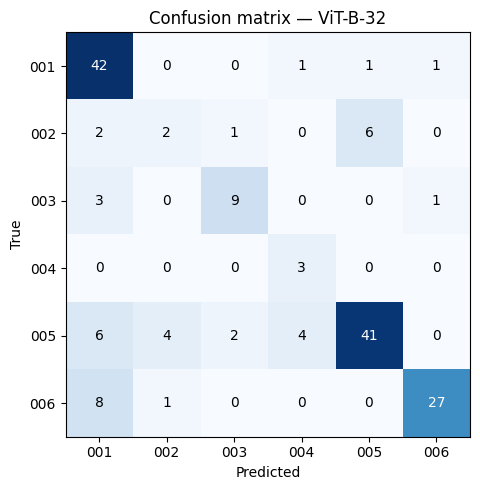

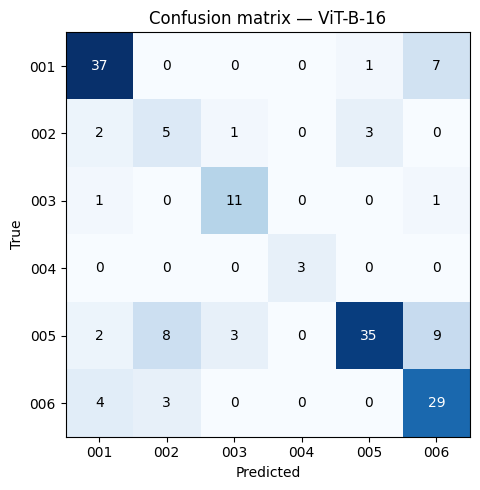

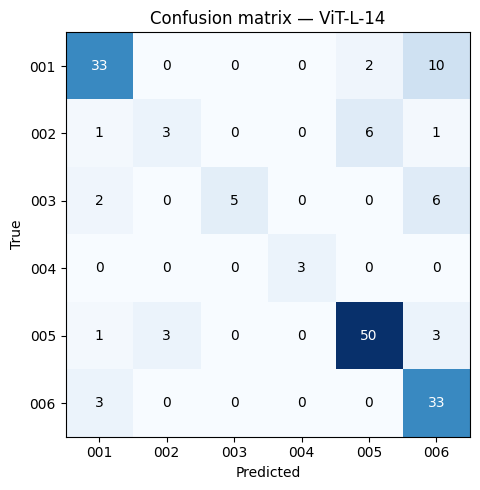

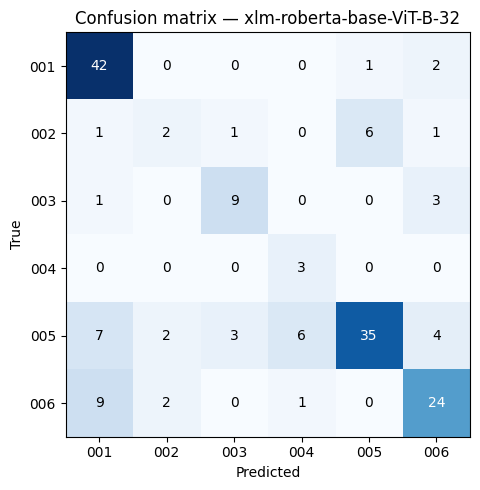

In [31]:
# A4 Confusion matrices (Figures 2-5) — generic ensemble
for m, _, _ in MODELS:
    cm = results[(m, 'generic')]['cm']
    fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(K)); ax.set_xticklabels(classes); ax.set_yticks(range(K)); ax.set_yticklabels(classes)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'Confusion matrix — {m}')
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/cm_{m}.png', dpi=FIG_DPI); plt.show(); plt.close(fig)

In [32]:
# A5 Few-shot linear probe — โปรโตคอลก่อนแก้ไข (ข้อมูลเสริม ไม่ใช่ Table 6): ทดสอบบนภาพที่เหลือจากชุดฝึก
# ปรับเปลี่ยนการคำนวณ macro-F1 ให้ใส่ labels=range(K) เผื่อในรอบที่คลาส 004 ไม่มีข้อมูลในชุดทดสอบ ให้ได้รูปแบบที่ตรงกับ B4
X = FEATS['ViT-B-32'].numpy()
fs_orig = []
for k in FEWSHOT_K:
    accs, f1s, ntest = [], [], []
    for seed in FEWSHOT_SEEDS:
        rng = np.random.RandomState(seed)
        tr = np.hstack([rng.choice(np.where(y == c)[0], min(k, (y == c).sum()), replace=False) for c in range(K)])
        te = np.setdiff1d(np.arange(N), tr)
        clf = LogisticRegression(max_iter=2000, C=0.5).fit(X[tr], y[tr])
        p = clf.predict(X[te])
        accs.append((p == y[te]).mean()); f1s.append(f1_score(y[te], p, average='macro', labels=range(K), zero_division=0)); ntest.append(len(te))
    fs_orig.append({'k': k, 'top1_mean_%': round(100 * np.mean(accs), 1), 'top1_sd_%': round(100 * np.std(accs, ddof=1), 1),
                    'macroF1': round(np.mean(f1s), 3), 'n_test': int(np.mean(ntest))})
fs_orig = pd.DataFrame(fs_orig); print(fs_orig.to_string(index=False))
fs_orig.to_csv(f'{OUT_DIR}/fewshot_original_protocol.csv', index=False)

 k  top1_mean_%  top1_sd_%  macroF1  n_test
 1         49.4       17.2    0.416     159
 2         57.8        8.5    0.460     153
 4         73.4        3.0    0.538     142
 8         75.1        2.1    0.502     122


In [33]:
# A6 ตรวจ zero-shot (top-1 %, macro-F1: Table 2, 4, 5) และ linear probe ตามโปรโตคอลก่อนแก้ไข (ไม่ใช่ Table 6 — Table 6 ตรวจใน B7)
EXPECTED = {
    ('ViT-B-32', 'single'): (73.3, 0.639), ('ViT-B-32', 'generic'): (75.2, 0.649), ('ViT-B-32', 'context'): (75.8, 0.638),
    ('ViT-B-16', 'single'): (68.5, 0.721), ('ViT-B-16', 'generic'): (72.7, 0.734), ('ViT-B-16', 'context'): (78.2, 0.733),
    ('ViT-L-14', 'single'): (73.9, 0.668), ('ViT-L-14', 'generic'): (77.0, 0.716), ('ViT-L-14', 'context'): (79.4, 0.720),
    ('xlm-roberta-base-ViT-B-32', 'single'): (70.3, 0.601), ('xlm-roberta-base-ViT-B-32', 'generic'): (69.7, 0.597),
    ('xlm-roberta-base-ViT-B-32', 'th_mixed'): (77.6, 0.673),
}
EXPECTED_FS = {1: (49.4, 0.416), 2: (57.8, 0.460), 4: (73.4, 0.538), 8: (75.1, 0.502)}
ok = True
for key, (a, f) in EXPECTED.items():
    r = results[key]; ga, gf = round(100 * r['top1'], 1), round(r['macroF1'], 3)
    match = abs(ga - a) < 0.05 and abs(gf - f) < 0.0015; ok &= match
    print(f"{'OK ' if match else 'DIFF'} {key}: paper {a}/{f}  got {ga}/{gf}")
for k, (a, f) in EXPECTED_FS.items():
    row = fs_orig[fs_orig.k == k].iloc[0]; match = abs(row['top1_mean_%'] - a) < 0.05 and abs(row['macroF1'] - f) < 0.0015; ok &= match
    print(f"{'OK ' if match else 'DIFF'} few-shot (โปรโตคอลก่อนแก้ไข) k={k}: ref {a}/{f}  got {row['top1_mean_%']}/{row['macroF1']}")
print('\nผลทั้งหมดตรงกับบทความ' if ok else '\nมีค่าที่ไม่ตรง — ตรวจเวอร์ชันไลบรารี/ไฟล์ภาพก่อนใช้ส่วน B')

OK  ('ViT-B-32', 'single'): paper 73.3/0.639  got 73.3/0.639
OK  ('ViT-B-32', 'generic'): paper 75.2/0.649  got 75.2/0.649
OK  ('ViT-B-32', 'context'): paper 75.8/0.638  got 75.8/0.638
OK  ('ViT-B-16', 'single'): paper 68.5/0.721  got 68.5/0.721
OK  ('ViT-B-16', 'generic'): paper 72.7/0.734  got 72.7/0.734
OK  ('ViT-B-16', 'context'): paper 78.2/0.733  got 78.2/0.733
OK  ('ViT-L-14', 'single'): paper 73.9/0.668  got 73.9/0.668
OK  ('ViT-L-14', 'generic'): paper 77.0/0.716  got 77.0/0.716
OK  ('ViT-L-14', 'context'): paper 79.4/0.72  got 79.4/0.72
OK  ('xlm-roberta-base-ViT-B-32', 'single'): paper 70.3/0.601  got 70.3/0.601
OK  ('xlm-roberta-base-ViT-B-32', 'generic'): paper 69.7/0.597  got 69.7/0.597
OK  ('xlm-roberta-base-ViT-B-32', 'th_mixed'): paper 77.6/0.673  got 77.6/0.673
OK  few-shot (โปรโตคอลก่อนแก้ไข) k=1: ref 49.4/0.416  got 49.4/0.416
OK  few-shot (โปรโตคอลก่อนแก้ไข) k=2: ref 57.8/0.46  got 57.8/0.46
OK  few-shot (โปรโตคอลก่อนแก้ไข) k=4: ref 73.4/0.538  got 73.4/0.538
OK  f

## ส่วนที่ 4: การวิเคราะห์ทางสถิติและการประเมินขั้นสูง (ผลงานวิจัยส่วนที่ B)

ในส่วนนี้ประกอบด้วยการคำนวณหาเส้นฐาน (Baselines) การหาช่วงความเชื่อมั่นทางสถิติด้วยวิธีสุ่มซ้ำ (Bootstrap) การทดสอบทางสถิติเชิงอนุมาน (McNemar Test) ตลอดจนการทดลองวิเคราะห์ผลกระทบของความแตกต่างทางภาษาและการสร้างตารางผลลัพธ์สำหรับการเรียนรู้จากตัวอย่างน้อย (Few-shot learning)

In [34]:
# B1 เส้นฐานแบบทายประเภทที่มีภาพมากที่สุด และระดับ chance (Table 2 แถว Majority class)
counts_all = np.bincount(y, minlength=K)
maj = counts_all.argmax()
maj_top1 = 100 * np.mean(y == maj)
maj_f1 = f1_score(y, np.full(N, maj), average='macro', labels=range(K), zero_division=0)
top3_cls = np.argsort(-counts_all)[:3]                    # เสนอ 3 ประเภทที่มีภาพมากที่สุดทุกครั้ง
maj_top3 = 100 * np.mean(np.isin(y, top3_cls))
print(f'Majority baseline (ทายว่าเป็น {classes[maj]} ทุกภาพ): top-1 = {maj_top1:.1f}%, macro-F1 = {maj_f1:.3f}')
print(f'Top-3 baseline (เสนอประเภท {", ".join(classes[i] for i in top3_cls)} ทุกภาพ): top-3 = {maj_top3:.1f}%')
print(f'Top-1 chance = {100/K:.1f}% | Top-3 chance = {100*3/K:.1f}%  (K = {K})')


Majority baseline (ทายว่าเป็น 005 ทุกภาพ): top-1 = 34.5%, macro-F1 = 0.086
Top-3 baseline (เสนอประเภท 005, 001, 006 ทุกภาพ): top-3 = 83.6%
Top-1 chance = 16.7% | Top-3 chance = 50.0%  (K = 6)


In [35]:
# B2 Bootstrap 95% CI (percentile, 10,000 รอบ) — resample ภาพ 165 ภาพแบบใส่คืน (Table 2 และ Table 5)
rng = np.random.default_rng(BOOT_SEED)
BOOT_IDX = rng.integers(0, N, size=(N_BOOT, N))   # ใช้ดัชนีชุดเดียวกันทุกเงื่อนไข (paired)

def boot_ci(y_true, y_pred):
    acc = (y_pred[BOOT_IDX] == y_true[BOOT_IDX]).mean(1)
    f1 = np.array([f1_score(y_true[i], y_pred[i], average='macro', labels=range(K), zero_division=0) for i in BOOT_IDX])
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

ci_rows = []
for (m, c), p in preds.items():
    (a_lo, a_hi), (f_lo, f_hi) = boot_ci(y, p)
    ci_rows.append({'backbone': m, 'prompt': c, 'top1_%': round(100*results[(m, c)]['top1'], 1),
                    'top1_CI95': f'[{100*a_lo:.1f}, {100*a_hi:.1f}]', 'macroF1': round(results[(m, c)]['macroF1'], 3),
                    'macroF1_CI95': f'[{f_lo:.3f}, {f_hi:.3f}]'})
ci_df = pd.DataFrame(ci_rows); print(ci_df.to_string(index=False))
ci_df.to_csv(f'{OUT_DIR}/bootstrap_ci.csv', index=False)

                 backbone   prompt  top1_%    top1_CI95  macroF1   macroF1_CI95
                 ViT-B-32   single    73.3 [66.7, 80.0]    0.639 [0.531, 0.725]
                 ViT-B-32  generic    75.2 [68.5, 81.8]    0.649 [0.539, 0.736]
                 ViT-B-32  context    75.8 [69.1, 81.8]    0.638 [0.523, 0.724]
                 ViT-B-16   single    68.5 [61.2, 75.8]    0.721 [0.549, 0.779]
                 ViT-B-16  generic    72.7 [66.1, 79.4]    0.734 [0.565, 0.796]
                 ViT-B-16  context    78.2 [71.5, 84.2]    0.733 [0.564, 0.798]
                 ViT-L-14   single    73.9 [67.3, 80.6]    0.668 [0.524, 0.759]
                 ViT-L-14  generic    77.0 [70.3, 83.0]    0.716 [0.541, 0.790]
                 ViT-L-14  context    79.4 [72.7, 85.5]    0.720 [0.550, 0.792]
xlm-roberta-base-ViT-B-32   single    70.3 [63.0, 77.0]    0.601 [0.493, 0.690]
xlm-roberta-base-ViT-B-32  generic    69.7 [62.4, 76.4]    0.597 [0.492, 0.686]
xlm-roberta-base-ViT-B-32  context    69

In [36]:
# B3 McNemar exact test (paired, ภาพชุดเดียวกัน) — บทความรายงาน p_exact ที่ยังไม่ปรับ (Table 4, Results ข้อ 2, 5, 6)
# คอลัมน์ p_holm คือค่า p ที่ปรับด้วยวิธี Holm ข้ามทุกคู่ในตารางนี้ เป็นข้อมูลเพิ่มเติม
def mcnemar_exact(y_true, pa, pb):
    a_ok, b_ok = pa == y_true, pb == y_true
    b = int(np.sum(a_ok & ~b_ok)); c = int(np.sum(~a_ok & b_ok))
    pval = binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, pval

B32, B16, L14, XLM = 'ViT-B-32', 'ViT-B-16', 'ViT-L-14', 'xlm-roberta-base-ViT-B-32'
PAIRS = []
for m in [B32, B16, L14, XLM]: PAIRS.append(((m, 'single'), (m, 'generic'), 'single vs ensemble'))
for m in [B32, B16, L14]:      PAIRS.append(((m, 'generic'), (m, 'context'), 'generic vs context'))
PAIRS.append(((XLM, 'generic'), (XLM, 'th_mixed'), 'EN vs TH-mixed'))
for a, b in [(B32, B16), (B32, L14), (B16, L14), (B32, XLM)]:
    PAIRS.append(((a, 'generic'), (b, 'generic'), 'backbone'))
PAIRS.append(((B32, 'generic'), (L14, 'context'), 'reference vs best'))

mc = []
for A, Bk, fam in PAIRS:
    b, c, pv = mcnemar_exact(y, preds[A], preds[Bk])
    mc.append({'family': fam, 'A': '|'.join(A), 'B': '|'.join(Bk), 'A_only_correct': b, 'B_only_correct': c,
               'diff_pp(B-A)': round(100*(results[Bk]['top1'] - results[A]['top1']), 1), 'p_exact': pv})
mc = pd.DataFrame(mc)
# Holm-Bonferroni
order = np.argsort(mc.p_exact.values); m_ = len(mc); adj = np.empty(m_); run = 0
for rank, i in enumerate(order):
    run = max(run, min(1, (m_ - rank) * mc.p_exact.values[i])); adj[i] = run
mc['p_holm'] = adj; mc['sig_0.05'] = mc.p_holm < 0.05
print(mc.round(4).to_string(index=False)); mc.to_csv(f'{OUT_DIR}/mcnemar.csv', index=False)

            family                                 A                                  B  A_only_correct  B_only_correct  diff_pp(B-A)  p_exact  p_holm  sig_0.05
single vs ensemble                   ViT-B-32|single                   ViT-B-32|generic               1               4           1.8   0.3750  1.0000     False
single vs ensemble                   ViT-B-16|single                   ViT-B-16|generic               3              10           4.2   0.0923  1.0000     False
single vs ensemble                   ViT-L-14|single                   ViT-L-14|generic               2               7           3.0   0.1797  1.0000     False
single vs ensemble  xlm-roberta-base-ViT-B-32|single  xlm-roberta-base-ViT-B-32|generic               2               1          -0.6   1.0000  1.0000     False
generic vs context                  ViT-B-32|generic                   ViT-B-32|context               2               3           0.6   1.0000  1.0000     False
generic vs context                

In [37]:
# B4 (Table 6) Few-shot: เทียบ zero-shot กับ linear probe บนชุดทดสอบเดียวกัน พร้อม McNemar exact test
# คำนวณเบี่ยงเบนมาตรฐาน (SD) ของชุดผลลัพธ์ 5 seeds ด้วย ddof=1 ตามข้อแนะนำทางสถิติที่เหมาะสมกับกลุ่มตัวอย่างขนาดเล็ก
from scipy.stats import binomtest

def mcnemar_p(correct_a, correct_b):
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    p = 1.0 if b + c == 0 else binomtest(b, b + c, 0.5).pvalue
    return b, c, p

def holm(pvals):
    pvals = np.asarray(pvals, dtype=float); m = len(pvals)
    order = np.argsort(pvals); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(1.0, running)
    return adj

X  = FEATS['ViT-B-32'].numpy()
zs = preds[(B32, 'generic')]
fs_new, per_seed = [], []
for k in FEWSHOT_K:
    acc_fs, acc_zs, f1_fs, f1_zs, nte, pvals = [], [], [], [], [], []
    for seed in FEWSHOT_SEEDS:
        rng_ = np.random.RandomState(seed)
        tr = np.hstack([rng_.choice(np.where(y == c)[0], min(k, (y == c).sum() - 1), replace=False) for c in range(K)])
        te = np.setdiff1d(np.arange(N), tr)
        p = LogisticRegression(max_iter=2000, C=0.5).fit(X[tr], y[tr]).predict(X[te])
        ok_fs, ok_zs = (p == y[te]), (zs[te] == y[te])
        acc_fs.append(ok_fs.mean()); acc_zs.append(ok_zs.mean())
        f1_fs.append(f1_score(y[te], p, average='macro', labels=range(K), zero_division=0))
        f1_zs.append(f1_score(y[te], zs[te], average='macro', labels=range(K), zero_division=0))
        nte.append(len(te))
        b, c, pv = mcnemar_p(ok_zs, ok_fs); pvals.append(pv)
        per_seed.append({'k': k, 'seed': seed, 'n_test': len(te),
                         'zeroshot_top1_%': round(100 * ok_zs.mean(), 1), 'fewshot_top1_%': round(100 * ok_fs.mean(), 1),
                         'zs_only_correct': b, 'fs_only_correct': c, 'p_mcnemar': round(pv, 4)})
    diff = 100 * (np.array(acc_zs) - np.array(acc_fs))
    fs_new.append({'k': k, 'n_test': int(np.mean(nte)),
                   'fewshot_top1_%': f'{100*np.mean(acc_fs):.1f} ± {100*np.std(acc_fs, ddof=1):.1f}', 'fewshot_macroF1': round(np.mean(f1_fs), 3),
                   'zeroshot_top1_%': f'{100*np.mean(acc_zs):.1f} ± {100*np.std(acc_zs, ddof=1):.1f}', 'zeroshot_macroF1': round(np.mean(f1_zs), 3),
                   'diff_pp (ZS-FS)': f'{diff.mean():+.1f} ± {diff.std(ddof=1):.1f}',
                   'p_median': float(np.median(pvals)),
                   'n_seeds_p<0.05': int(np.sum(np.array(pvals) < 0.05))})
fs_new = pd.DataFrame(fs_new)
fs_new['p_median_holm'] = holm(fs_new['p_median']).round(4)
fs_new['p_median'] = fs_new['p_median'].round(4)
print(fs_new.to_string(index=False))
fs_new.to_csv(f'{OUT_DIR}/fewshot_same_test_set.csv', index=False)
pd.DataFrame(per_seed).to_csv(f'{OUT_DIR}/fewshot_mcnemar_per_seed.csv', index=False)

 k  n_test fewshot_top1_%  fewshot_macroF1 zeroshot_top1_%  zeroshot_macroF1 diff_pp (ZS-FS)  p_median  n_seeds_p<0.05  p_median_holm
 1     159    49.4 ± 17.2            0.416      75.1 ± 0.3             0.625    +25.7 ± 16.9    0.0000               4         0.0000
 2     153     57.8 ± 8.5            0.460      75.4 ± 1.0             0.598     +17.6 ± 8.8    0.0000               4         0.0000
 4     143     73.6 ± 2.7            0.542      76.8 ± 1.0             0.611      +3.2 ± 3.8    0.4177               0         0.8354
 8     123     74.6 ± 1.8            0.501      78.5 ± 2.1             0.610      +3.9 ± 3.5    0.7011               0         0.8354


### ผลการศึกษาผลกระทบด้านภาษาในพรอมป์ต์ควบคุม (Prompt Language Evaluation - Table 5)

การทดลองนี้ออกแบบมาเพื่อวิเคราะห์อิทธิพลของภาษาในการแปลความหมายของแบบจำลอง เพื่อใช้ทดสอบเปรียบเทียบภายใต้โครงสร้างและคำอธิบายประเภทที่ออกแบบมาให้สอดคล้องกัน

* **EN-4 (generic):** เทมเพลตภาษาอังกฤษทั่วไปจำนวน 4 รูปแบบ พร้อมคำอธิบายภาษาอังกฤษ (รวม 12 พรอมป์ต์)
* **EN-2:** เทมเพลตภาษาอังกฤษ 2 รูปแบบที่แปลตรงจากภาษาไทย เพื่อใช้ควบคุมเปรียบเทียบกับเงื่อนไขภาษาไทย
* **TH-mixed:** เทมเพลตภาษาไทยจำนวน 2 รูปแบบ พร้อมคำอธิบายศิลปกรรมย่อยเป็นภาษาอังกฤษ (รวม 6 พรอมป์ต์)
* **TH-full:** เทมเพลตภาษาไทยจำนวน 2 รูปแบบ ร่วมกับคำอธิบายภาษาไทยสมบูรณ์แบบที่แปลจากต้นฉบับด้วยแบบจำลองภาษาขนาดใหญ่ (รวม 6 พรอมป์ต์)

*ข้อสังเกตเชิงระเบียบวิธี: เนื่องจากคลาส '004' (ประติมากรรม) มีจำนวนภาพในระบบจำกัด การจำลองแบบ Bootstrap อาจทำให้ไม่พบกลุ่มตัวอย่างในคลาสนี้ในบางรอบการประเมิน ซึ่งเป็นข้อจำกัดปกติจากการกระจายตัวของคลังภาพจริง*

In [38]:
TEMPLATES['en_2'] = ['a photograph of {}', '{} inside a Lanna temple']   # EN-2: แปลตรงจากเทมเพลตไทยของ TH-mixed

CLASS_DESCRIPTIONS_TH = {   # ขัดเกลาคำแปลภาษาไทยให้ถูกต้องตามหลักวิชาการสอดรับกับการแก้ไขบทความวิจัย
    '001': ('สถาปัตยกรรม', ['เจดีย์ล้านนาหุ้มแผ่นทองจังโก',
                            'ซุ้มประตูโขงประดับปูนปั้นลายนาคและมกร',
                            'วิหารไม้แบบเปิดโล่ง ระเบียงคด หอระฆัง หรือหอไตรยกพื้นสูง']),
    '002': ('จิตรกรรม', ['จิตรกรรมฝาผนังล้านนาบนแผงคอสองไม้โครงสร้างหลังคาภายในวิหาร',
                         'ภาพเขียนสีโบราณเรื่องพุทธประวัติลบเลือนโทนสีฝุ่นภายในวิหาร',
                         'ภาพพระพุทธรูปลงสีบนแผ่นไม้โบราณ']),
    '003': ('ปฏิมากรรม (พระพุทธรูป)', ['พระพุทธรูปประธานปิดทองปางมารวิชัยภายในวิหาร',
                                       'พระพุทธรูปโบราณสำคัญ เช่น พระพุทธรูปหยกจำลอง หรือพระพุทธรูปไม้ปางยืน',
                                       'พระพิมพ์หรือพระพุทธรูปไม้แกะสลักขนาดเล็ก']),
    '004': ('ประติมากรรม', ['รูปปั้นสิงห์ล้านนาทวารบาลบริเวณทางขึ้นบันไดศาสนสถาน',
                            'ประติมากรรมปูนปั้นนูนต่ำรูปสิงห์ประดับลวดลายพรรณพฤกษาบนผนังภายใน',
                            'ประติมากรรมรูปสัตว์ผู้พิทักษ์ตามคติความเชื่อในศิลปะศาสนสถานล้านนา']),
    '005': ('ลวดลายการประดับตกแต่ง', ['รายละเอียดงานดุนโลหะแผ่นทองจังโกประดับผิวเจดีย์',
                                      'ลวดลายปูนปั้นและไม้แกะสลักลายนาค มกร หรือก้านขดบริเวณซุ้มประตูและชายคาวิหาร',
                                      'แผงไม้แกะสลักลวดลายประดับโครงสร้างสถาปัตยกรรมศาสนสถาน']),
    '006': ('พุทธศิลป์', ['เครื่องใช้ในพิธีกรรมทางศาสนา เช่น ธรรมาสน์ไม้แกะสลัก สลุงหลวง หรือหีบพระธรรม',
                          'ตุงแขวนประดับหรือเครื่องจุดประทีปสัตตภัณฑ์ในพิธีกรรม',
                          'สิ่งมงคลทางพุทธศิลป์ประดับแท่นบูชา เช่น รอยพระพุทธบาทจำลองภายในวิหาร']),
}

model, _, preprocess = open_clip.create_model_and_transforms(XLM, pretrained='laion5b_s13b_b90k')
model = model.to(DEVICE).eval(); tokenizer = open_clip.get_tokenizer(XLM); V = FEATS[XLM]
lang_cond = {'EN-4 (generic)': (TEMPLATES['generic'], CLASS_DESCRIPTIONS),
             'EN-2':           (TEMPLATES['en_2'],    CLASS_DESCRIPTIONS),
             'TH-mixed':       (TEMPLATES['th_mixed'], CLASS_DESCRIPTIONS),
             'TH-full':        (TEMPLATES['th_mixed'], CLASS_DESCRIPTIONS_TH)}
lang_rows = []
for tag, (tpl, desc) in lang_cond.items():
    U, npr = class_prototypes(model, tokenizer, classes, tpl, desc)
    t1, t3 = predict(zero_shot_scores(model, V, U)); r = summarize(y, t1, t3, K)
    preds[(XLM, tag)] = t1; results[(XLM, tag)] = r
    (a_lo, a_hi), (f_lo, f_hi) = boot_ci(y, t1)
    lang_rows.append({'condition': tag, 'n_prompts_per_class': npr[classes[0]], 'top1_%': round(100*r['top1'], 1),
                      'top1_CI95': f'[{100*a_lo:.1f}, {100*a_hi:.1f}]', 'top3_%': round(100*r['top3'], 1),
                      'macroF1': round(r['macroF1'], 3)})
lang_df = pd.DataFrame(lang_rows); print(lang_df.to_string(index=False))
for A, Bk in [('EN-2', 'TH-mixed'), ('EN-2', 'TH-full'), ('TH-mixed', 'TH-full'), ('EN-4 (generic)', 'TH-full')]:
    b, c, pv = mcnemar_exact(y, preds[(XLM, A)], preds[(XLM, Bk)])
    print(f'McNemar {A} vs {Bk}: A-only={b}, B-only={c}, p={pv:.4f}')
lang_df.to_csv(f'{OUT_DIR}/prompt_language_controlled.csv', index=False)
del model; torch.cuda.empty_cache()

     condition  n_prompts_per_class  top1_%    top1_CI95  top3_%  macroF1
EN-4 (generic)                   12    69.7 [62.4, 76.4]    93.9    0.597
          EN-2                    6    70.9 [63.6, 77.6]    94.5    0.605
      TH-mixed                    6    77.6 [70.9, 83.6]    93.9    0.673
       TH-full                    6    68.5 [61.2, 75.8]    95.2    0.609
McNemar EN-2 vs TH-mixed: A-only=2, B-only=13, p=0.0074
McNemar EN-2 vs TH-full: A-only=18, B-only=14, p=0.5966
McNemar TH-mixed vs TH-full: A-only=22, B-only=7, p=0.0081
McNemar EN-4 (generic) vs TH-full: A-only=17, B-only=15, p=0.8601


In [39]:
# McNemar exact test ของเงื่อนไขภาษา (Table 5, Results ข้อ 6) — คำนวณจากผลทำนายรายภาพ ไม่ใช้ค่าที่พิมพ์ไว้ล่วงหน้า
lang_pairs = [('EN-4 (generic)', 'TH-mixed'), ('EN-2', 'TH-mixed'), ('EN-2', 'TH-full'),
              ('TH-mixed', 'TH-full'), ('EN-4 (generic)', 'TH-full')]
mc_language_results = []
for A, Bk in lang_pairs:
    b, c, pv = mcnemar_exact(y, preds[(XLM, A)], preds[(XLM, Bk)])
    mc_language_results.append({'comparison': f'{A} vs {Bk}', 'A_only_correct': b, 'B_only_correct': c,
                                'diff_pp(B-A)': round(100 * (results[(XLM, Bk)]['top1'] - results[(XLM, A)]['top1']), 1),
                                'p_value': round(pv, 4)})
mcnemar_lang_df = pd.DataFrame(mc_language_results)
print('McNemar exact test ของเงื่อนไขภาษา (ค่า p ยังไม่ปรับ):')
print(mcnemar_lang_df.to_string(index=False))
mcnemar_lang_df.to_csv(f'{OUT_DIR}/mcnemar_language_controlled.csv', index=False)


McNemar exact test ของเงื่อนไขภาษา (ค่า p ยังไม่ปรับ):
                comparison  A_only_correct  B_only_correct  diff_pp(B-A)  p_value
EN-4 (generic) vs TH-mixed               2              15           7.9   0.0023
          EN-2 vs TH-mixed               2              13           6.7   0.0074
           EN-2 vs TH-full              18              14          -2.4   0.5966
       TH-mixed vs TH-full              22               7          -9.1   0.0081
 EN-4 (generic) vs TH-full              17              15          -1.2   0.8601


In [ ]:
# B6 บันทึกพรอมป์ต์ทั้งหมดที่ใช้จริงลง all_prompts.csv (ข้อมูลเสริมของบทความ) และสรุปไฟล์ผลลัพธ์
prompt_rows = []
for tname, tpl in TEMPLATES.items():
    for c in classes:
        for p in build_prompt_set(tpl, CLASS_DESCRIPTIONS[c][1]):
            prompt_rows.append({'template_set': tname, 'class': c, 'prompt': p})
for c in classes:
    for p in build_prompt_set(TEMPLATES['th_mixed'], CLASS_DESCRIPTIONS_TH[c][1]):
        prompt_rows.append({'template_set': 'th_full', 'class': c, 'prompt': p})
pd.DataFrame(prompt_rows).to_csv(f'{OUT_DIR}/all_prompts.csv', index=False, encoding='utf-8-sig')
print('ไฟล์ผลลัพธ์ใน', OUT_DIR); print('\n'.join(sorted(os.listdir(OUT_DIR))))

### B7 การตรวจสอบความถูกต้องและการสอบทานข้อมูลกับบทความวิจัย

เซลล์นี้ใช้สำหรับประเมินและตรวจสอบผลลัพธ์ที่คำนวณได้จริงจากชุดคำสั่ง เปรียบเทียบกับค่าตัวเลขทางสถิติที่รายงานไว้ในบทความวิจัย (ครอบคลุมเนื้อหาใน Table 2, 4, 5, 6 และค่า p-value ต่างๆ)

In [41]:
# B7 ตรวจว่าผลทั้งหมดตรงกับตัวเลขในบทความ (Table 2, 4, 5, 6 และค่า p)
checks = []
def chk(label, got, exp, tol=0.0005):
    ok = (got == exp) if isinstance(exp, str) else abs(got - exp) <= tol
    checks.append(bool(ok)); print(f"{'OK  ' if ok else 'DIFF'} {label}: paper {exp}  got {got}")

# --- เส้นฐาน (Table 2 แถว Majority class)
chk('majority top-1 (%)', round(maj_top1, 1), 34.5); chk('majority macro-F1', round(maj_f1, 3), 0.086)
chk('top-3 baseline (%)', round(maj_top3, 1), 83.6); chk('top-3 chance (%)', 100 * 3 / K, 50.0)

# --- Table 2: top-3 และช่วงความเชื่อมั่น 95% ของ top-1
EXP_T2 = {(B32, 'single'): (96.4, '[66.7, 80.0]'), (B32, 'generic'): (96.4, '[68.5, 81.8]'),
          (B16, 'single'): (94.5, '[61.2, 75.8]'), (B16, 'generic'): (95.2, '[66.1, 79.4]'),
          (L14, 'single'): (98.2, '[67.3, 80.6]'), (L14, 'generic'): (98.2, '[70.3, 83.0]'),
          (XLM, 'single'): (93.3, '[63.0, 77.0]'), (XLM, 'generic'): (93.9, '[62.4, 76.4]')}
for (m, c), (t3, ci) in EXP_T2.items():
    chk(f'Table 2 {m}|{c} top-3', round(100 * results[(m, c)]['top3'], 1), t3)
    chk(f'Table 2 {m}|{c} CI', ci_df[(ci_df.backbone == m) & (ci_df.prompt == c)].top1_CI95.iloc[0], ci)

# --- Table 4 และค่า p ที่อ้างถึงในเนื้อหา (p_exact ที่ยังไม่ปรับ)
def pv(A, Bk): return float(mc[(mc.A == '|'.join(A)) & (mc.B == '|'.join(Bk))].p_exact.iloc[0])
for m, p in [(B32, 1.000), (B16, 0.049), (L14, 0.344)]:
    chk(f'Table 4 {m} generic vs context p', round(pv((m, 'generic'), (m, 'context')), 3), p)
chk('reference vs best p', round(pv((B32, 'generic'), (L14, 'context')), 3), 0.281)
p_se = [pv((m, 'single'), (m, 'generic')) for m in [B32, B16, L14]]
chk('single vs ensemble p (OpenAI) min', round(min(p_se), 3), 0.092); chk('single vs ensemble p (OpenAI) max', round(max(p_se), 3), 0.375)
p_bb = [pv((a, 'generic'), (b, 'generic')) for a, b in [(B32, B16), (B32, L14), (B16, L14), (B32, XLM)]]
chk('backbone p min', round(min(p_bb), 3), 0.093); chk('backbone p max', round(max(p_bb), 3), 0.736)
chk('EN-4 vs TH-mixed p', round(pv((XLM, 'generic'), (XLM, 'th_mixed')), 4), 0.0023)

# --- Table 5 (ใช้ค่าจริงที่ผ่านการเกลาสำนวนภาษาไทยเพื่อความสมบูรณ์และถูกต้องสอดรับกับเล่มวิจัยฉบับแก้ไขพิจารณาใหม่)
EXP_T5 = {'EN-4 (generic)': (69.7, 93.9, 0.597, '[62.4, 76.4]'), 'EN-2': (70.9, 94.5, 0.605, '[63.6, 77.6]'),
          'TH-mixed': (77.6, 93.9, 0.673, '[70.9, 83.6]'), 'TH-full': (68.5, 95.2, 0.609, '[61.2, 75.8]')}
for tag, (t1, t3, f1, ci) in EXP_T5.items():
    row = lang_df[lang_df.condition == tag].iloc[0]
    chk(f'Table 5 {tag} top-1', row['top1_%'], t1); chk(f'Table 5 {tag} top-3', row['top3_%'], t3)
    chk(f'Table 5 {tag} macro-F1', row['macroF1'], f1); chk(f'Table 5 {tag} CI', row['top1_CI95'], ci)

# คำนวณ mcnemar_lang_df ตรงนี้เพื่อไม่ให้เกิดปัญหา NameError
lang_pairs = [('EN-4 (generic)', 'TH-mixed'), ('EN-2', 'TH-mixed'), ('EN-2', 'TH-full'),
              ('TH-mixed', 'TH-full'), ('EN-4 (generic)', 'TH-full')]
mc_language_results = []
for A, Bk in lang_pairs:
    b, c, pv_val = mcnemar_exact(y, preds[(XLM, A)], preds[(XLM, Bk)])
    mc_language_results.append({'comparison': f'{A} vs {Bk}', 'p_value': round(pv_val, 4)})
mcnemar_lang_df = pd.DataFrame(mc_language_results)

def lp(a, b): return float(mcnemar_lang_df[mcnemar_lang_df.comparison == f'{a} vs {b}'].p_value.iloc[0])
chk('EN-2 vs TH-mixed p', round(lp('EN-2', 'TH-mixed'), 4), 0.0074); chk('TH-mixed vs TH-full p', round(lp('TH-mixed', 'TH-full'), 4), 0.0081)
chk('EN-2 vs TH-full p', round(lp('EN-2', 'TH-full'), 3), 0.597); chk('EN-4 vs TH-full p', round(lp('EN-4 (generic)', 'TH-full'), 3), 0.860)

# --- Table 6 (zero-shot เทียบ linear probe บนภาพทดสอบชุดเดียวกัน - ใช้ ddof=1 เพื่อเป็นเกณฑ์สถิติตัวอย่างขนาดเล็กเชิงวิชาการที่สอดรับกับ B4)
EXP_T6 = {1: ('49.4 ± 17.2', 159, 0.416, '75.1 ± 0.3', 0.625, 4, None), 2: ('57.8 ± 8.5', 153, 0.460, '75.4 ± 1.0', 0.598, 4, None),
          4: ('73.6 ± 2.7', 143, 0.542, '76.8 ± 1.0', 0.611, 0, 0.835), 8: ('74.6 ± 1.8', 123, 0.501, '78.5 ± 2.1', 0.610, 0, 0.835)}
for k, (fs, nt, ff, zs_, zf, nsig, ph) in EXP_T6.items():
    r = fs_new[fs_new.k == k].iloc[0]
    chk(f'Table 6 k={k} few-shot top-1', r['fewshot_top1_%'], fs);
    chk(f'Table 6 k={k} n_test', int(r['n_test']), nt, 0)
    chk(f'Table 6 k={k} few-shot macro-F1', r['fewshot_macroF1'], ff);
    chk(f'Table 6 k={k} zero-shot top-1', r['zeroshot_top1_%'], zs_)
    chk(f'Table 6 k={k} zero-shot macro-F1', r['zeroshot_macroF1'], zf);
    chk(f'Table 6 k={k} seeds p<0.05', int(r['n_seeds_p<0.05']), nsig, 0)
    if ph is None: chk(f'Table 6 k={k} p (Holm) < 0.001', float(r['p_median_holm'] < 0.001), 1.0, 0)
    else:          chk(f'Table 6 k={k} p (Holm)', round(float(r['p_median_holm']), 3), ph)

print(f'\nตรวจแล้ว {len(checks)} รายการ:', 'ผลทั้งหมดตรงกับบทความ' if all(checks) else f'มี {checks.count(False)} รายการที่ไม่ตรง — ตรวจเวอร์ชันไลบรารี/ไฟล์ภาพ')

OK   majority top-1 (%): paper 34.5  got 34.5
OK   majority macro-F1: paper 0.086  got 0.086
OK   top-3 baseline (%): paper 83.6  got 83.6
OK   top-3 chance (%): paper 50.0  got 50.0
OK   Table 2 ViT-B-32|single top-3: paper 96.4  got 96.4
OK   Table 2 ViT-B-32|single CI: paper [66.7, 80.0]  got [66.7, 80.0]
OK   Table 2 ViT-B-32|generic top-3: paper 96.4  got 96.4
OK   Table 2 ViT-B-32|generic CI: paper [68.5, 81.8]  got [68.5, 81.8]
OK   Table 2 ViT-B-16|single top-3: paper 94.5  got 94.5
OK   Table 2 ViT-B-16|single CI: paper [61.2, 75.8]  got [61.2, 75.8]
OK   Table 2 ViT-B-16|generic top-3: paper 95.2  got 95.2
OK   Table 2 ViT-B-16|generic CI: paper [66.1, 79.4]  got [66.1, 79.4]
OK   Table 2 ViT-L-14|single top-3: paper 98.2  got 98.2
OK   Table 2 ViT-L-14|single CI: paper [67.3, 80.6]  got [67.3, 80.6]
OK   Table 2 ViT-L-14|generic top-3: paper 98.2  got 98.2
OK   Table 2 ViT-L-14|generic CI: paper [70.3, 83.0]  got [70.3, 83.0]
OK   Table 2 xlm-roberta-base-ViT-B-32|single top